# Importing The Packages

In [1]:
import pandas as pd
import numpy as np
from nltk.stem import WordNetLemmatizer
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re
import spacy
from nltk.corpus import sentiwordnet as swn
from IPython.display import clear_output
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import plotly
plotly.offline.init_notebook_mode (connected = True)

In [2]:
import sys
print(sys.executable)

C:\Users\rkim8\anaconda3\envs\yolo_project\python.exe


# Importing The Data

In [1]:
data=pd.read_csv('dataFolder/sentiment_analysis.csv', encoding="latin-1")

NameError: name 'pd' is not defined

In [4]:
data.columns

Index(['textID', 'text', 'selected_text', 'sentiment', 'Time of Tweet',
       'Age of User', 'Country', 'Population -2020', 'Land Area (Km²)',
       'Density (P/Km²)'],
      dtype='str')

In [5]:
data = data.drop(columns=["textID", "selected_text", "Time of Tweet", "Age of User", "Country", "Population -2020", "Land Area (Km²)", "Density (P/Km²)"])


In [6]:
data.head(5)

,text,sentiment
0,"I`d have responded, if I were going",neutral
1,Sooo SAD I will miss you here in San Diego!!!,negative
2,my boss is bullying me...,negative
3,what interview! leave me alone,negative
4,"Sons of ****, why couldn`t they put them on t...",negative


In [7]:
data["text"] = data["text"].fillna('')

# Making two copies of Reviews to edit

In [8]:
# Replacing Positive -> 1 and Negative -> 0

data.replace({"positive":1,"negative":0},inplace=True)

,text,sentiment
0,"I`d have responded, if I were going",neutral
1,Sooo SAD I will miss you here in San Diego!!!,0
2,my boss is bullying me...,0
3,what interview! leave me alone,0
4,"Sons of ****, why couldn`t they put them on t...",0
...,...,...
27476,wish we could come see u on Denver husband l...,0
27477,I`ve wondered about rake to. The client has ...,0
27478,Yay good for both of you. Enjoy the break - y...,1
27479,But it was worth it ****.,1


In [9]:
#Edits After Removing Stopwords
Edited_Review = data['text'].copy()
data['text_without_stopwords'] = Edited_Review

# Having a look at 1st five reviews in the data

In [10]:
data.head(5)

,text,sentiment,text_without_stopwords
0,"I`d have responded, if I were going",neutral,"I`d have responded, if I were going"
1,Sooo SAD I will miss you here in San Diego!!!,0,Sooo SAD I will miss you here in San Diego!!!
2,my boss is bullying me...,0,my boss is bullying me...
3,what interview! leave me alone,0,what interview! leave me alone
4,"Sons of ****, why couldn`t they put them on t...",0,"Sons of ****, why couldn`t they put them on t..."


# Preprocessing The Data

In [11]:
# Function to preprocess Reviews data
def preprocess_Reviews_data(data,name):
    # Proprocessing the data
    data[name]=data[name].str.lower()
    # Code to remove the Hashtags from the text
    data[name]=data[name].apply(lambda x:re.sub(r'\B#\S+','',x))
    # Code to remove the links from the text
    data[name]=data[name].apply(lambda x:re.sub(r"http\S+", "", x))
    # Code to remove the Special characters from the text 
    data[name]=data[name].apply(lambda x:' '.join(re.findall(r"[\w']+", x)))
    # Code to substitute the multiple spaces with single spaces
    data[name]=data[name].apply(lambda x:re.sub(r'\s+', ' ', x, flags=re.I))
    # Code to remove all the single characters in the text
    data[name]=data[name].apply(lambda x:re.sub(r'\s+[a-zA-Z]\s+', ' ', x))
    # Remove the twitter handlers
    data[name]=data[name].apply(lambda x:re.sub('@[^\s]+',' ',x))

# Function to tokenize and remove the stopwords    
def rem_stopwords_tokenize(data,name):
      
    def getting(sen):
        example_sent = sen
        
        filtered_sentence = [] 

        stop_words = set(stopwords.words('english')) 

        word_tokens = word_tokenize(example_sent) 
        
        filtered_sentence = [w for w in word_tokens if not w in stop_words] 
        
        return filtered_sentence
    # Using "getting(sen)" function to append edited sentence to data
    x=[]
    for i in data[name].values:
        x.append(getting(i))
    data[name]=x


# Lemmatization Function

In [12]:
lemmatizer = WordNetLemmatizer()
def Lemmatization(data,name):
    def getting2(sen):

        if isinstance(sen, list):
            sen = ' '.join(sen)
        
        example = sen
        output_sentence =[]
        word_tokens2 = word_tokenize(example)
        lemmatized_output = [lemmatizer.lemmatize(w) for w in word_tokens2]
        
        # Remove characters which have length less than 2  
        without_single_chr = [word for word in lemmatized_output if len(word) > 2]
        # Remove numbers
        cleaned_data_title = [word for word in without_single_chr if not word.isnumeric()]
        
        return cleaned_data_title
    # Using "getting2(sen)" function to append edited sentence to data
    x=[]
    for i in data[name].values:
        x.append(getting2(i))
    data[name]=x

# Converting all the texts back to sentences

In [13]:
def make_sentences(data,name):
    data[name]=data[name].apply(lambda x:' '.join([i for i in x]))
    # Removing double spaces if created
    data[name]=data[name].apply(lambda x:re.sub(r'\s+', ' ', x, flags=re.I))

In [18]:
data["text_without_stopwords"] = data["text_without_stopwords"].fillna('').astype(str)
data

,text,sentiment,text_without_stopwords
0,"I`d have responded, if I were going",neutral,"I`d have responded, if I were going"
1,Sooo SAD I will miss you here in San Diego!!!,0,Sooo SAD I will miss you here in San Diego!!!
2,my boss is bullying me...,0,my boss is bullying me...
3,what interview! leave me alone,0,what interview! leave me alone
4,"Sons of ****, why couldn`t they put them on t...",0,"Sons of ****, why couldn`t they put them on t..."
...,...,...,...
27476,wish we could come see u on Denver husband l...,0,wish we could come see u on Denver husband l...
27477,I`ve wondered about rake to. The client has ...,0,I`ve wondered about rake to. The client has ...
27478,Yay good for both of you. Enjoy the break - y...,1,Yay good for both of you. Enjoy the break - y...
27479,But it was worth it ****.,1,But it was worth it ****.


In [19]:
# Using the preprocessing function to preprocess the hotel data
preprocess_Reviews_data(data,'text_without_stopwords')
# Using tokenizer and removing the stopwords
rem_stopwords_tokenize(data,'text_without_stopwords')
# use regex to get rid of spaces and
make_sentences(data,'text_without_stopwords')

#Edits After Lemmatization
final_Edit = data['text_without_stopwords'].copy()
data["After_lemmatization"] = final_Edit

# Using the Lemmatization function to lemmatize the hotel data
Lemmatization(data,'After_lemmatization')
# Converting all the texts back to sentences
make_sentences(data,'After_lemmatization')

# Results of Preprocessing data (Removing stopwords & Lemmatization)

In [20]:
data.head(6)

,text,sentiment,text_without_stopwords,After_lemmatization
0,"I`d have responded, if I were going",neutral,responded going,responded going
1,Sooo SAD I will miss you here in San Diego!!!,0,sooo sad miss san diego,sooo sad miss san diego
2,my boss is bullying me...,0,boss bullying,bos bullying
3,what interview! leave me alone,0,interview leave alone,interview leave alone
4,"Sons of ****, why couldn`t they put them on t...",0,sons put releases already bought,son put release already bought
5,http://www.dothebouncy.com/smf - some shameles...,neutral,shameless plugging best rangers forum earth,shameless plugging best ranger forum earth


So when we are working with sentiwordnet we need to know the characterstic of the word for which we want to know the sentiment . So for finding that position of the word here we are gonna use nltk which tells us about the position of the word which then is used to get the sentiment using the sentiwordnet . We then average out the score for both the positive and the negative score from the whole sentence .
The positions compatible with the sentiwordnet are:
* n - NOUN
* v - VERB
* a - ADJECTIVE
* s - ADJECTIVE SATELLITE
* r - ADVERB

In [21]:
import nltk
import ssl
from nltk.corpus import wordnet as wn
from nltk.corpus import sentiwordnet as swn
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords

In [22]:
pos=neg=obj=count=0

postagging = []

for review in data['After_lemmatization']:
    list = word_tokenize(review)
    postagging.append(nltk.pos_tag(list))
    """
    returns: NN, VB, JJ, RB, VBD, VBG, NNS, etc
    """

data['pos_tags'] = postagging

def penn_to_wn(tag):
    if tag.startswith('J'):
        return wn.ADJ #return "a"
    elif tag.startswith('N'):
        return wn.NOUN #return "n"
    elif tag.startswith('R'):
        return wn.ADV #return R
    elif tag.startswith('V'):
        return wn.VERB #return V
    return None

"""
WordNet tags (what wn.ADJ, wn.NOUN etc. are): 'n', 'v', 'a', 'r', 's' — only 5 broad categories.
"""


# Returns list of pos-neg and objective score. But returns empty list if not present in senti wordnet.
def get_sentiment(word,tag):
    wn_tag = penn_to_wn(tag)


    if wn_tag not in (wn.NOUN, wn.ADJ, wn.ADV):
        return []

    #Lemmatization
    lemma = lemmatizer.lemmatize(word, pos=wn_tag)
    if not lemma:
        return []

    #Synset is a special kind of a simple interface that is present in NLTK to look up words in WordNet. 
    #Synset instances are the groupings of synonymous words that express the same concept. 
    #Some of the words have only one Synset and some have several.
    synsets = wn.synsets(word, pos=wn_tag)
    if not synsets:
        return []

    # Take the first sense, the most common
    synset = synsets[0]
    swn_synset = swn.senti_synset(synset.name())

    return [synset.name(), swn_synset.pos_score(),swn_synset.neg_score(),swn_synset.obj_score()]

    pos=neg=obj=count=0
    
    ###################################################################################
senti_score = []

for pos_val in data['pos_tags']:
    senti_val = [get_sentiment(x,y) for (x,y) in pos_val]
    for score in senti_val:
        try:
            pos = pos + score[1]  #positive score is stored at 2nd position
            neg = neg + score[2]  #negative score is stored at 3rd position
        except:
            continue
    senti_score.append(pos - neg)
    pos=neg=0    
    
data['senti_score'] = senti_score
print(data['senti_score'])

print(data.head)

0        0.000
1       -0.625
2        0.000
3        0.000
4        0.250
         ...  
27476    0.500
27477    0.875
27478    0.750
27479    0.000
27480    0.125
Name: senti_score, Length: 27481, dtype: float64
<bound method NDFrame.head of                                                     text sentiment  \
0                    I`d have responded, if I were going   neutral   
1          Sooo SAD I will miss you here in San Diego!!!         0   
2                              my boss is bullying me...         0   
3                         what interview! leave me alone         0   
4       Sons of ****, why couldn`t they put them on t...         0   
...                                                  ...       ...   
27476   wish we could come see u on Denver  husband l...         0   
27477   I`ve wondered about rake to.  The client has ...         0   
27478   Yay good for both of you. Enjoy the break - y...         1   
27479                         But it was worth it  ****.

In [45]:
overall=[]
for i in range(len(data)):
    if data['senti_score'][i]>= 0.05:
        overall.append('Positive')
    elif data['senti_score'][i]<= -0.05:
        overall.append('Negative')
    else:
        overall.append('Neutral')
data['Overall Sentiment']=overall
data['Overall Sentiment'] = data['Overall Sentiment'].str.lower()

In [47]:
# Replacing Positive -> 1 and Negative -> 0 #reverse it

data.replace({1:"positive", 0:"negative"},inplace=True)

,text,sentiment,text_without_stopwords,After_lemmatization,pos_tags,senti_score,Overall Sentiment,reviews_text_new
0,"I`d have responded, if I were going",neutral,responded going,responded going,"[(responded, VBD), (going, VBG)]",negative,neutral,responded going
1,Sooo SAD I will miss you here in San Diego!!!,negative,sooo sad miss san diego,sooo sad miss san diego,"[(sooo, JJ), (sad, JJ), (miss, NN), (san, NN),...",-0.625,negative,sooo sad miss san diego
2,my boss is bullying me...,negative,boss bullying,bos bullying,"[(bos, NNS), (bullying, VBG)]",negative,neutral,bos bullying
3,what interview! leave me alone,negative,interview leave alone,interview leave alone,"[(interview, NN), (leave, VBP), (alone, RB)]",negative,neutral,interview leave alone
4,"Sons of ****, why couldn`t they put them on t...",negative,sons put releases already bought,son put release already bought,"[(son, NN), (put, VBD), (release, NN), (alread...",0.25,positive,son put release already bought
...,...,...,...,...,...,...,...,...
27476,wish we could come see u on Denver husband l...,negative,wish could come see denver husband lost job af...,wish could come see denver husband lost job af...,"[(wish, NN), (could, MD), (come, VB), (see, VB...",0.5,positive,wish could come see denver husband lost job af...
27477,I`ve wondered about rake to. The client has ...,negative,wondered rake client made clear net force devs...,wondered rake client made clear net force devs...,"[(wondered, VBN), (rake, NN), (client, NN), (m...",0.875,positive,wondered rake client made clear net force devs...
27478,Yay good for both of you. Enjoy the break - y...,positive,yay good enjoy break probably need hectic week...,yay good enjoy break probably need hectic week...,"[(yay, RB), (good, JJ), (enjoy, NN), (break, N...",0.75,positive,yay good enjoy break probably need hectic week...
27479,But it was worth it ****.,positive,worth,worth,"[(worth, NN)]",negative,neutral,worth


In [48]:
data.head(10)

,text,sentiment,text_without_stopwords,After_lemmatization,pos_tags,senti_score,Overall Sentiment,reviews_text_new
0,"I`d have responded, if I were going",neutral,responded going,responded going,"[(responded, VBD), (going, VBG)]",negative,neutral,responded going
1,Sooo SAD I will miss you here in San Diego!!!,negative,sooo sad miss san diego,sooo sad miss san diego,"[(sooo, JJ), (sad, JJ), (miss, NN), (san, NN),...",-0.625,negative,sooo sad miss san diego
2,my boss is bullying me...,negative,boss bullying,bos bullying,"[(bos, NNS), (bullying, VBG)]",negative,neutral,bos bullying
3,what interview! leave me alone,negative,interview leave alone,interview leave alone,"[(interview, NN), (leave, VBP), (alone, RB)]",negative,neutral,interview leave alone
4,"Sons of ****, why couldn`t they put them on t...",negative,sons put releases already bought,son put release already bought,"[(son, NN), (put, VBD), (release, NN), (alread...",0.25,positive,son put release already bought
5,http://www.dothebouncy.com/smf - some shameles...,neutral,shameless plugging best rangers forum earth,shameless plugging best ranger forum earth,"[(shameless, NN), (plugging, VBG), (best, JJS)...",0.75,positive,shameless plugging best ranger forum earth
6,2am feedings for the baby are fun when he is a...,positive,2am feedings baby fun smiles coos,2am feeding baby fun smile coo,"[(2am, CD), (feeding, VBG), (baby, NN), (fun, ...",0.5,positive,2am feeding baby fun smile coo
7,Soooo high,neutral,soooo high,soooo high,"[(soooo, RB), (high, JJ)]",-0.125,negative,soooo high
8,Both of you,neutral,,,[],negative,neutral,
9,Journey!? Wow... u just became cooler. hehe....,positive,journey wow became cooler hehe possible,journey wow became cooler hehe possible,"[(journey, NN), (wow, NN), (became, VBD), (coo...",0.5,positive,journey wow became cooler hehe possible


In [49]:
from sklearn.metrics import classification_report
# Print a classification report
print(classification_report(data["Overall Sentiment"],data["sentiment"]))

              precision    recall  f1-score   support

    negative       0.38      0.50      0.43      5957
     neutral       0.48      0.55      0.51      9764
    positive       0.67      0.49      0.56     11760

    accuracy                           0.51     27481
   macro avg       0.51      0.51      0.50     27481
weighted avg       0.54      0.51      0.52     27481



In [54]:
print(data["Overall Sentiment"].value_counts().head(10))


Overall Sentiment
positive    11760
neutral      9764
negative     5957
Name: count, dtype: int64


<Axes: xlabel='count', ylabel='Overall Sentiment'>

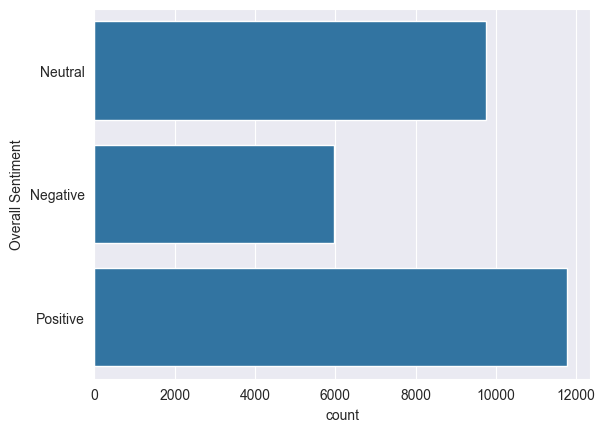

In [25]:
import seaborn as sns
sns.countplot(data['Overall Sentiment'])

In [26]:
data['reviews_text_new'] = data['After_lemmatization'].copy()

# Building a machine learning model

In [38]:
data[['reviews_text_new', "text"]]

,reviews_text_new,text
0,responded going,"I`d have responded, if I were going"
1,sooo sad miss san diego,Sooo SAD I will miss you here in San Diego!!!
2,bos bullying,my boss is bullying me...
3,interview leave alone,what interview! leave me alone
4,son put release already bought,"Sons of ****, why couldn`t they put them on t..."
...,...,...
27476,wish could come see denver husband lost job af...,wish we could come see u on Denver husband l...
27477,wondered rake client made clear net force devs...,I`ve wondered about rake to. The client has ...
27478,yay good enjoy break probably need hectic week...,Yay good for both of you. Enjoy the break - y...
27479,worth,But it was worth it ****.


# Bag-of-words

In [39]:
### Creating a python object of the class CountVectorizer
from sklearn.feature_extraction.text import CountVectorizer
bow_counts = CountVectorizer(tokenizer= word_tokenize, # type of tokenization
                             ngram_range=(1,3)) # number of n-grams

bow_data = bow_counts.fit_transform(data['reviews_text_new'])

C:\Users\rkim8\anaconda3\envs\yolo_project\Lib\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


# Divide into training and test sets

In [40]:
from sklearn.model_selection import train_test_split
X_train_bow, X_test_bow, y_train_bow, y_test_bow = train_test_split(bow_data, # Features
                                                                    data['Overall Sentiment'], # Target variable
                                                                    test_size = 0.2, # 20% test size
                                                                    random_state = 0) # random

# Applying logistic regression

In [41]:
from sklearn.linear_model import LogisticRegression
### Training the model 
lr_model_all = LogisticRegression() # Logistic regression
lr_model_all.fit(X_train_bow, y_train_bow) # Fitting a logistic regression model

## Predicting the output
test_pred_lr_all = lr_model_all.predict(X_test_bow) # Class prediction


## Calculate key performance metrics

from sklearn.metrics import classification_report
# Print a classification report
print(classification_report(y_test_bow,test_pred_lr_all))

              precision    recall  f1-score   support

    Negative       0.81      0.64      0.71      1219
     Neutral       0.74      0.87      0.80      1943
    Positive       0.85      0.83      0.84      2335

    accuracy                           0.80      5497
   macro avg       0.80      0.78      0.78      5497
weighted avg       0.80      0.80      0.80      5497



# TF-IDF model

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
noise_words = []
### Creating a python object of the class CountVectorizer
tfidf_counts = TfidfVectorizer(tokenizer= word_tokenize, # type of tokenization
                               stop_words=noise_words, # List of stopwords
                               ngram_range=(1,1)) # number of n-grams

tfidf_data = tfidf_counts.fit_transform(data['reviews_text_new'])

C:\Users\rkim8\anaconda3\envs\yolo_project\Lib\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [43]:
X_train_tfidf, X_test_tfidf, y_train_tfidf, y_test_tfidf = train_test_split(tfidf_data,
                                                                            data['Overall Sentiment'],
                                                                            test_size = 0.2,
                                                                            random_state = 0)

In [44]:
### Setting up the model class
lr_model_tf_idf = LogisticRegression()

## Training the model 
lr_model_tf_idf.fit(X_train_tfidf,y_train_tfidf)

## Prediciting the results
test_pred_lr_all = lr_model_tf_idf.predict(X_test_tfidf)

## Calculate key performance metrics


# Print a classification report
print(classification_report(y_test_tfidf,test_pred_lr_all))

              precision    recall  f1-score   support

    Negative       0.84      0.62      0.71      1219
     Neutral       0.72      0.86      0.79      1943
    Positive       0.85      0.83      0.84      2335

    accuracy                           0.79      5497
   macro avg       0.80      0.77      0.78      5497
weighted avg       0.80      0.79      0.79      5497



# Takeaway
Overall Sentiword net is HORRIBLE. A lot worse than Vader or TextBlob. However, using a logistic regression is the best out of Vader, TextBlob or sentiwordnet.